In [6]:
!pip install -q torchmetrics torch-fidelity kagglehub

import os, glob, time, random
from collections import defaultdict
import numpy as np
import pandas as pd
import torch, torch.nn as nn
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from torch.utils.data import DataLoader, TensorDataset
import torchvision.utils as vutils

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

def set_seed(s=42):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()

Device: cuda


In [7]:
CLASSES      = ["pizza", "sushi", "donuts", "hamburger", "ice_cream"]
IMGS_PER_CLS = 1000          # Food-101 has 1000 images per class
IMG_SIZE     = 64
NZ           = 100           # latent vector size
BATCH_SIZE   = 128
EPOCHS       = 60            # same for both models
LR, BETA1    = 2e-4, 0.5
IMG_EXTS     = (".jpg", ".jpeg", ".png")

In [8]:
import kagglehub
DATA_PATH = kagglehub.dataset_download("dansbecker/food-101")
print("Downloaded to:", DATA_PATH)

Using Colab cache for faster access to the 'food-101' dataset.
Downloaded to: /kaggle/input/food-101


In [12]:
def is_real_image(f):
    return f.lower().endswith(IMG_EXTS) and not f.startswith(".")

found = defaultdict(list)          # class name -> [(folder, image_count), ...]
for root, dirs, files in os.walk(DATA_PATH):
    if "__MACOSX" in root.split(os.sep):      # skip macOS junk folders
        continue
    name = os.path.basename(root)
    if name in CLASSES:
        n = sum(is_real_image(f) for _, _, fs in os.walk(root) for f in fs)
        found[name].append((root, n))

CLASS_DIR = {}
for c in CLASSES:
    assert c in found, f"Class '{c}' not found under {DATA_PATH}"
    best = max(found[c], key=lambda t: t[1])      # folder with the most real images
    CLASS_DIR[c] = best[0]
    print(f"{c:10s}: {best[1]} images  ->  {best[0]}")

pizza     : 1000 images  ->  /kaggle/input/food-101/food-101/food-101/images/pizza
sushi     : 1000 images  ->  /kaggle/input/food-101/food-101/food-101/images/sushi
donuts    : 1000 images  ->  /kaggle/input/food-101/food-101/food-101/images/donuts
hamburger : 1000 images  ->  /kaggle/input/food-101/food-101/food-101/images/hamburger
ice_cream : 1000 images  ->  /kaggle/input/food-101/food-101/food-101/images/ice_cream


In [13]:
from PIL import ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True      # tolerate slightly truncated JPEGs

def list_images(cls):
    files = []
    for r, _, fs in os.walk(CLASS_DIR[cls]):
        files += [os.path.join(r, f) for f in fs
                  if f.lower().endswith(IMG_EXTS) and not f.startswith(".")]   # skip ._hidden files
    return sorted(files)

def load_image(path, size=IMG_SIZE):
    img = Image.open(path).convert("RGB")
    w, h = img.size
    s = min(w, h)                                    # center crop to square
    left, top = (w - s)//2, (h - s)//2
    img = img.crop((left, top, left+s, top+s)).resize((size, size), Image.BICUBIC)
    return np.asarray(img, dtype=np.uint8)

imgs, bad_files = [], []
for c in CLASSES:
    files = list_images(c)
    assert len(files) > 0, f"No images found for '{c}' in {CLASS_DIR[c]}"
    count = 0
    for f in tqdm(files, desc=c):
        if count >= IMGS_PER_CLS:
            break
        try:
            imgs.append(load_image(f))
            count += 1
        except Exception as e:                       # corrupt / unreadable file -> skip
            bad_files.append((f, type(e).__name__))
    print(f"{c}: loaded {count} images")

print(f"\nSkipped {len(bad_files)} unreadable files")
for f, e in bad_files[:10]:
    print("  ", e, "->", f)

data_uint8 = torch.from_numpy(np.stack(imgs)).permute(0, 3, 1, 2)   # N,3,64,64 uint8
print("Dataset tensor:", data_uint8.shape)

data = data_uint8.float().div(127.5).sub(1.0)        # scale to [-1, 1]
loader = DataLoader(TensorDataset(data), batch_size=BATCH_SIZE,
                    shuffle=True, drop_last=True)

pizza:   0%|          | 0/1000 [00:00<?, ?it/s]

pizza: loaded 1000 images


sushi:   0%|          | 0/1000 [00:00<?, ?it/s]

sushi: loaded 1000 images


donuts:   0%|          | 0/1000 [00:00<?, ?it/s]

donuts: loaded 1000 images


hamburger:   0%|          | 0/1000 [00:00<?, ?it/s]

hamburger: loaded 1000 images


ice_cream:   0%|          | 0/1000 [00:00<?, ?it/s]

ice_cream: loaded 1000 images

Skipped 0 unreadable files
Dataset tensor: torch.Size([5000, 3, 64, 64])


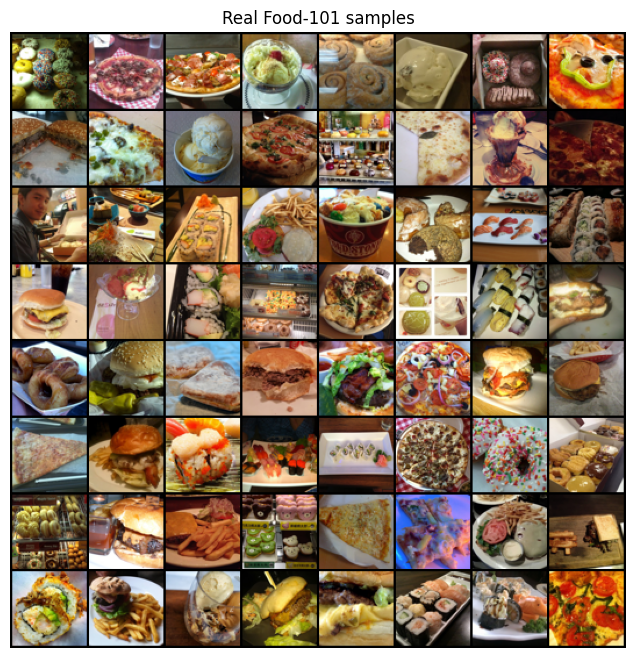

In [14]:
def show_grid(tensor, title, nrow=8, figsize=(8, 8)):
    grid = vutils.make_grid(tensor[:nrow*nrow].cpu(), nrow=nrow,
                            normalize=True, value_range=(-1, 1), padding=2)
    plt.figure(figsize=figsize); plt.axis("off"); plt.title(title)
    plt.imshow(grid.permute(1, 2, 0)); plt.show()

show_grid(data[torch.randperm(len(data))[:64]], "Real Food-101 samples")

In [19]:
from IPython.display import clear_output

def new_run(G, D, name):
    """Create a training state that can be resumed."""
    G, D = G.to(device), D.to(device)
    return {
        "name": name, "G": G, "D": D,
        "optG": torch.optim.Adam(G.parameters(), lr=LR, betas=(BETA1, 0.999)),
        "optD": torch.optim.Adam(D.parameters(), lr=LR, betas=(BETA1, 0.999)),
        "fixed_noise": torch.randn(64, NZ, device=device),
        "hist": {"G_loss": [], "D_loss": [], "D_real": [], "D_fake": [],
                 "snapshots": {}, "train_time": 0.0},
        "epoch": 0,
    }

def train_epochs(run, n_epochs, show_every=10):
    """Train n_epochs more epochs, one epoch at a time, logging each one."""
    G, D, h = run["G"], run["D"], run["hist"]
    optG, optD, name = run["optG"], run["optD"], run["name"]
    criterion = nn.BCEWithLogitsLoss()
    t0 = time.time()

    for _ in range(n_epochs):
        run["epoch"] += 1
        ep = run["epoch"]
        G.train(); D.train()
        g_l, d_l, dr, df = [], [], [], []

        for (real,) in loader:
            real = real.to(device)
            b = real.size(0)
            # light augmentation: random horizontal flip
            flip = torch.rand(b, device=device) < 0.5
            real = torch.where(flip.view(-1, 1, 1, 1), real.flip(3), real)

            real_lbl = torch.full((b,), 0.9, device=device)   # one-sided label smoothing
            fake_lbl = torch.zeros(b, device=device)

            # ---- Discriminator ----
            fake = G(torch.randn(b, NZ, device=device))
            out_real, out_fake = D(real), D(fake.detach())
            loss_D = criterion(out_real, real_lbl) + criterion(out_fake, fake_lbl)
            optD.zero_grad(); loss_D.backward(); optD.step()

            # ---- Generator ----
            loss_G = criterion(D(fake), torch.ones(b, device=device))
            optG.zero_grad(); loss_G.backward(); optG.step()

            g_l.append(loss_G.item()); d_l.append(loss_D.item())
            dr.append(torch.sigmoid(out_real).mean().item())
            df.append(torch.sigmoid(out_fake).mean().item())

        h["G_loss"].append(np.mean(g_l)); h["D_loss"].append(np.mean(d_l))
        h["D_real"].append(np.mean(dr));  h["D_fake"].append(np.mean(df))

        # one line per epoch
        print(f"[{name}] Epoch {ep:3d} | D: {h['D_loss'][-1]:.3f} | G: {h['G_loss'][-1]:.3f} | "
              f"D(x): {h['D_real'][-1]:.2f} | D(G(z)): {h['D_fake'][-1]:.2f}")

        # save a snapshot every 5 epochs for the progress plot, and display samples
        if ep == 1 or ep % 5 == 0:
            G.eval()
            with torch.no_grad():
                h["snapshots"][ep] = G(run["fixed_noise"]).cpu()
        if ep % show_every == 0:
            show_grid(h["snapshots"][ep], f"{name} – epoch {ep}", nrow=8, figsize=(6, 6))

    h["train_time"] += time.time() - t0
    print(f"{name}: {run['epoch']} epochs done, total training time {h['train_time']/60:.1f} min")
    return h

def plot_history(h, name):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(h["G_loss"], label="Generator"); ax[0].plot(h["D_loss"], label="Discriminator")
    ax[0].set_title(f"{name}: Losses"); ax[0].set_xlabel("Epoch"); ax[0].legend()
    ax[1].plot(h["D_real"], label="D(x) real"); ax[1].plot(h["D_fake"], label="D(G(z)) fake")
    ax[1].set_title(f"{name}: Discriminator outputs"); ax[1].set_xlabel("Epoch"); ax[1].legend()
    plt.show()

def show_progress(h, name):
    eps = sorted(h["snapshots"].keys())
    pick = sorted(set([eps[0], eps[len(eps)//3], eps[2*len(eps)//3], eps[-1]]))
    fig, axs = plt.subplots(1, len(pick), figsize=(5*len(pick), 5.5))
    axs = np.atleast_1d(axs)
    for a, e in zip(axs, pick):
        g = vutils.make_grid(h["snapshots"][e][:36], nrow=6, normalize=True, value_range=(-1, 1))
        a.imshow(g.permute(1, 2, 0)); a.axis("off"); a.set_title(f"{name} – epoch {e}")
    plt.show()

def count_params(m): return sum(p.numel() for p in m.parameters())

In [16]:
IMG_DIM = 3 * IMG_SIZE * IMG_SIZE   # 12288

class VanillaG(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(NZ, 256),   nn.LeakyReLU(0.2),
            nn.Linear(256, 512),  nn.LeakyReLU(0.2),
            nn.Linear(512, 1024), nn.LeakyReLU(0.2),
            nn.Linear(1024, IMG_DIM), nn.Tanh()
        )
    def forward(self, z):
        return self.net(z).view(-1, 3, IMG_SIZE, IMG_SIZE)

class VanillaD(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(IMG_DIM, 1024), nn.LeakyReLU(0.2), nn.Dropout(0.3),
            nn.Linear(1024, 512),     nn.LeakyReLU(0.2), nn.Dropout(0.3),
            nn.Linear(512, 256),      nn.LeakyReLU(0.2), nn.Dropout(0.3),
            nn.Linear(256, 1)
        )
    def forward(self, x):
        return self.net(x).view(-1)

set_seed()
G_van, D_van = VanillaG(), VanillaD()
print(G_van); print(D_van)
print(f"Vanilla G params: {count_params(G_van):,} | D params: {count_params(D_van):,}")

VanillaG(
  (net): Sequential(
    (0): Linear(in_features=100, out_features=256, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=256, out_features=512, bias=True)
    (3): LeakyReLU(negative_slope=0.2)
    (4): Linear(in_features=512, out_features=1024, bias=True)
    (5): LeakyReLU(negative_slope=0.2)
    (6): Linear(in_features=1024, out_features=12288, bias=True)
    (7): Tanh()
  )
)
VanillaD(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=12288, out_features=1024, bias=True)
    (2): LeakyReLU(negative_slope=0.2)
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=1024, out_features=512, bias=True)
    (5): LeakyReLU(negative_slope=0.2)
    (6): Dropout(p=0.3, inplace=False)
    (7): Linear(in_features=512, out_features=256, bias=True)
    (8): LeakyReLU(negative_slope=0.2)
    (9): Dropout(p=0.3, inplace=False)
    (10): Linear(in_features=256, out_features=1, bias=True)
  )
)
Vanilla G para

[VanillaGAN] Epoch   1 | D: 1.036 | G: 1.797 | D(x): 0.63 | D(G(z)): 0.29
[VanillaGAN] Epoch   2 | D: 1.077 | G: 1.719 | D(x): 0.62 | D(G(z)): 0.30
[VanillaGAN] Epoch   3 | D: 1.098 | G: 1.665 | D(x): 0.61 | D(G(z)): 0.31
[VanillaGAN] Epoch   4 | D: 1.114 | G: 1.624 | D(x): 0.61 | D(G(z)): 0.32
[VanillaGAN] Epoch   5 | D: 1.096 | G: 1.706 | D(x): 0.62 | D(G(z)): 0.30
[VanillaGAN] Epoch   6 | D: 1.100 | G: 1.620 | D(x): 0.61 | D(G(z)): 0.31
[VanillaGAN] Epoch   7 | D: 1.083 | G: 1.631 | D(x): 0.62 | D(G(z)): 0.31
[VanillaGAN] Epoch   8 | D: 1.070 | G: 1.669 | D(x): 0.63 | D(G(z)): 0.30
[VanillaGAN] Epoch   9 | D: 1.083 | G: 1.659 | D(x): 0.62 | D(G(z)): 0.30
[VanillaGAN] Epoch  10 | D: 1.052 | G: 1.618 | D(x): 0.64 | D(G(z)): 0.30
[VanillaGAN] Epoch  11 | D: 1.063 | G: 1.625 | D(x): 0.64 | D(G(z)): 0.30
[VanillaGAN] Epoch  12 | D: 1.029 | G: 1.683 | D(x): 0.65 | D(G(z)): 0.29
[VanillaGAN] Epoch  13 | D: 1.078 | G: 1.656 | D(x): 0.63 | D(G(z)): 0.31
[VanillaGAN] Epoch  14 | D: 1.069 | G:

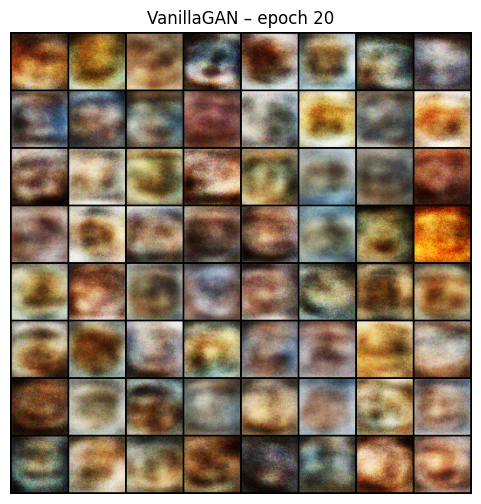

[VanillaGAN] Epoch  21 | D: 1.074 | G: 1.608 | D(x): 0.62 | D(G(z)): 0.30
[VanillaGAN] Epoch  22 | D: 1.035 | G: 1.711 | D(x): 0.64 | D(G(z)): 0.29
[VanillaGAN] Epoch  23 | D: 1.061 | G: 1.749 | D(x): 0.63 | D(G(z)): 0.29
[VanillaGAN] Epoch  24 | D: 1.057 | G: 1.694 | D(x): 0.63 | D(G(z)): 0.30
[VanillaGAN] Epoch  25 | D: 1.070 | G: 1.614 | D(x): 0.62 | D(G(z)): 0.30
[VanillaGAN] Epoch  26 | D: 1.049 | G: 1.660 | D(x): 0.63 | D(G(z)): 0.29
[VanillaGAN] Epoch  27 | D: 1.050 | G: 1.660 | D(x): 0.63 | D(G(z)): 0.29
[VanillaGAN] Epoch  28 | D: 1.064 | G: 1.648 | D(x): 0.62 | D(G(z)): 0.30
[VanillaGAN] Epoch  29 | D: 1.043 | G: 1.706 | D(x): 0.63 | D(G(z)): 0.29
[VanillaGAN] Epoch  30 | D: 1.066 | G: 1.672 | D(x): 0.62 | D(G(z)): 0.30
[VanillaGAN] Epoch  31 | D: 1.035 | G: 1.733 | D(x): 0.64 | D(G(z)): 0.28
[VanillaGAN] Epoch  32 | D: 1.032 | G: 1.673 | D(x): 0.64 | D(G(z)): 0.28
[VanillaGAN] Epoch  33 | D: 1.036 | G: 1.672 | D(x): 0.64 | D(G(z)): 0.29
[VanillaGAN] Epoch  34 | D: 1.076 | G:

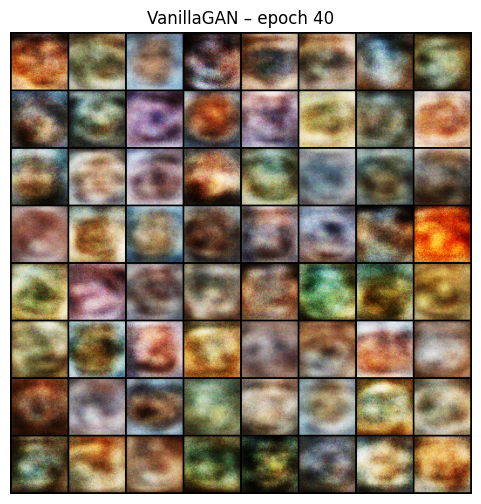

[VanillaGAN] Epoch  41 | D: 1.063 | G: 1.662 | D(x): 0.62 | D(G(z)): 0.29
[VanillaGAN] Epoch  42 | D: 1.057 | G: 1.677 | D(x): 0.63 | D(G(z)): 0.29
[VanillaGAN] Epoch  43 | D: 1.080 | G: 1.624 | D(x): 0.61 | D(G(z)): 0.30
[VanillaGAN] Epoch  44 | D: 1.075 | G: 1.649 | D(x): 0.62 | D(G(z)): 0.30
[VanillaGAN] Epoch  45 | D: 1.073 | G: 1.647 | D(x): 0.63 | D(G(z)): 0.30
[VanillaGAN] Epoch  46 | D: 1.128 | G: 1.610 | D(x): 0.59 | D(G(z)): 0.31
[VanillaGAN] Epoch  47 | D: 1.101 | G: 1.643 | D(x): 0.61 | D(G(z)): 0.31
[VanillaGAN] Epoch  48 | D: 1.088 | G: 1.611 | D(x): 0.61 | D(G(z)): 0.30
[VanillaGAN] Epoch  49 | D: 1.063 | G: 1.594 | D(x): 0.62 | D(G(z)): 0.30
[VanillaGAN] Epoch  50 | D: 1.095 | G: 1.621 | D(x): 0.61 | D(G(z)): 0.30
[VanillaGAN] Epoch  51 | D: 1.080 | G: 1.635 | D(x): 0.62 | D(G(z)): 0.30
[VanillaGAN] Epoch  52 | D: 1.090 | G: 1.669 | D(x): 0.61 | D(G(z)): 0.30
[VanillaGAN] Epoch  53 | D: 1.077 | G: 1.586 | D(x): 0.61 | D(G(z)): 0.31
[VanillaGAN] Epoch  54 | D: 1.107 | G:

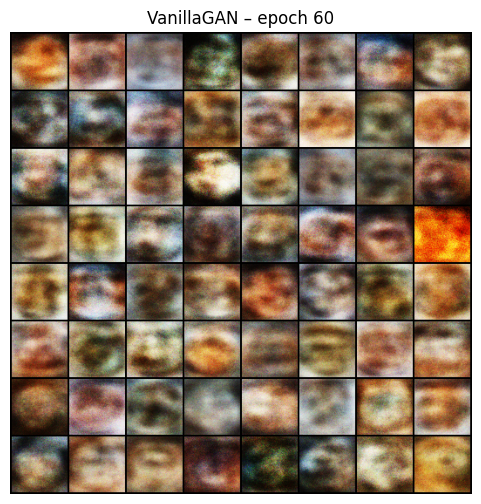

[VanillaGAN] Epoch  61 | D: 1.069 | G: 1.582 | D(x): 0.62 | D(G(z)): 0.31
[VanillaGAN] Epoch  62 | D: 1.059 | G: 1.676 | D(x): 0.62 | D(G(z)): 0.29
[VanillaGAN] Epoch  63 | D: 1.071 | G: 1.667 | D(x): 0.62 | D(G(z)): 0.29
[VanillaGAN] Epoch  64 | D: 1.105 | G: 1.561 | D(x): 0.60 | D(G(z)): 0.31
[VanillaGAN] Epoch  65 | D: 1.091 | G: 1.577 | D(x): 0.61 | D(G(z)): 0.31
[VanillaGAN] Epoch  66 | D: 1.103 | G: 1.523 | D(x): 0.60 | D(G(z)): 0.31
[VanillaGAN] Epoch  67 | D: 1.098 | G: 1.533 | D(x): 0.61 | D(G(z)): 0.31
[VanillaGAN] Epoch  68 | D: 1.072 | G: 1.622 | D(x): 0.62 | D(G(z)): 0.30
[VanillaGAN] Epoch  69 | D: 1.122 | G: 1.576 | D(x): 0.60 | D(G(z)): 0.31
[VanillaGAN] Epoch  70 | D: 1.125 | G: 1.488 | D(x): 0.59 | D(G(z)): 0.33
[VanillaGAN] Epoch  71 | D: 1.098 | G: 1.564 | D(x): 0.60 | D(G(z)): 0.31
[VanillaGAN] Epoch  72 | D: 1.130 | G: 1.496 | D(x): 0.59 | D(G(z)): 0.32
[VanillaGAN] Epoch  73 | D: 1.127 | G: 1.494 | D(x): 0.59 | D(G(z)): 0.33
[VanillaGAN] Epoch  74 | D: 1.107 | G:

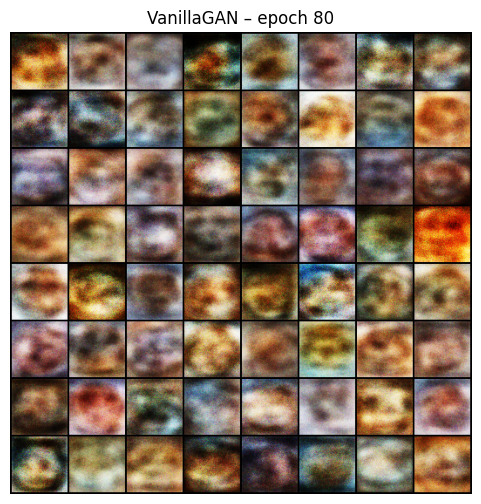

[VanillaGAN] Epoch  81 | D: 1.105 | G: 1.525 | D(x): 0.60 | D(G(z)): 0.32
[VanillaGAN] Epoch  82 | D: 1.134 | G: 1.463 | D(x): 0.59 | D(G(z)): 0.33
[VanillaGAN] Epoch  83 | D: 1.099 | G: 1.471 | D(x): 0.60 | D(G(z)): 0.32
[VanillaGAN] Epoch  84 | D: 1.113 | G: 1.506 | D(x): 0.60 | D(G(z)): 0.32
[VanillaGAN] Epoch  85 | D: 1.121 | G: 1.466 | D(x): 0.59 | D(G(z)): 0.32
[VanillaGAN] Epoch  86 | D: 1.102 | G: 1.446 | D(x): 0.60 | D(G(z)): 0.32
[VanillaGAN] Epoch  87 | D: 1.121 | G: 1.453 | D(x): 0.60 | D(G(z)): 0.32
[VanillaGAN] Epoch  88 | D: 1.124 | G: 1.449 | D(x): 0.59 | D(G(z)): 0.32
[VanillaGAN] Epoch  89 | D: 1.114 | G: 1.429 | D(x): 0.60 | D(G(z)): 0.33
[VanillaGAN] Epoch  90 | D: 1.116 | G: 1.447 | D(x): 0.60 | D(G(z)): 0.33
[VanillaGAN] Epoch  91 | D: 1.088 | G: 1.460 | D(x): 0.61 | D(G(z)): 0.31
[VanillaGAN] Epoch  92 | D: 1.121 | G: 1.461 | D(x): 0.60 | D(G(z)): 0.32
[VanillaGAN] Epoch  93 | D: 1.125 | G: 1.452 | D(x): 0.59 | D(G(z)): 0.32
[VanillaGAN] Epoch  94 | D: 1.142 | G:

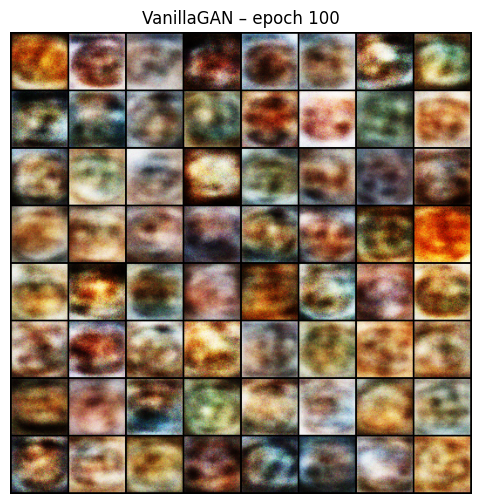

[VanillaGAN] Epoch 101 | D: 1.121 | G: 1.478 | D(x): 0.59 | D(G(z)): 0.32
[VanillaGAN] Epoch 102 | D: 1.125 | G: 1.451 | D(x): 0.59 | D(G(z)): 0.33
[VanillaGAN] Epoch 103 | D: 1.148 | G: 1.389 | D(x): 0.58 | D(G(z)): 0.33
[VanillaGAN] Epoch 104 | D: 1.122 | G: 1.408 | D(x): 0.59 | D(G(z)): 0.33
[VanillaGAN] Epoch 105 | D: 1.161 | G: 1.354 | D(x): 0.58 | D(G(z)): 0.34
[VanillaGAN] Epoch 106 | D: 1.127 | G: 1.401 | D(x): 0.59 | D(G(z)): 0.33
[VanillaGAN] Epoch 107 | D: 1.136 | G: 1.399 | D(x): 0.58 | D(G(z)): 0.33
[VanillaGAN] Epoch 108 | D: 1.124 | G: 1.445 | D(x): 0.59 | D(G(z)): 0.33
[VanillaGAN] Epoch 109 | D: 1.155 | G: 1.391 | D(x): 0.57 | D(G(z)): 0.34
[VanillaGAN] Epoch 110 | D: 1.156 | G: 1.377 | D(x): 0.57 | D(G(z)): 0.34
[VanillaGAN] Epoch 111 | D: 1.160 | G: 1.406 | D(x): 0.57 | D(G(z)): 0.33
[VanillaGAN] Epoch 112 | D: 1.141 | G: 1.434 | D(x): 0.57 | D(G(z)): 0.33
[VanillaGAN] Epoch 113 | D: 1.123 | G: 1.451 | D(x): 0.59 | D(G(z)): 0.32
[VanillaGAN] Epoch 114 | D: 1.162 | G:

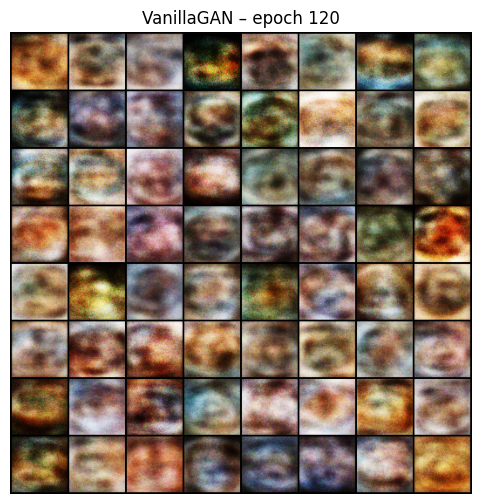

[VanillaGAN] Epoch 121 | D: 1.133 | G: 1.366 | D(x): 0.59 | D(G(z)): 0.34
[VanillaGAN] Epoch 122 | D: 1.135 | G: 1.400 | D(x): 0.59 | D(G(z)): 0.34
[VanillaGAN] Epoch 123 | D: 1.165 | G: 1.335 | D(x): 0.57 | D(G(z)): 0.35
[VanillaGAN] Epoch 124 | D: 1.153 | G: 1.349 | D(x): 0.58 | D(G(z)): 0.34
[VanillaGAN] Epoch 125 | D: 1.105 | G: 1.397 | D(x): 0.60 | D(G(z)): 0.33
[VanillaGAN] Epoch 126 | D: 1.164 | G: 1.323 | D(x): 0.58 | D(G(z)): 0.35
[VanillaGAN] Epoch 127 | D: 1.166 | G: 1.351 | D(x): 0.56 | D(G(z)): 0.34
[VanillaGAN] Epoch 128 | D: 1.167 | G: 1.366 | D(x): 0.57 | D(G(z)): 0.34
[VanillaGAN] Epoch 129 | D: 1.159 | G: 1.361 | D(x): 0.57 | D(G(z)): 0.34
[VanillaGAN] Epoch 130 | D: 1.161 | G: 1.432 | D(x): 0.57 | D(G(z)): 0.34
[VanillaGAN] Epoch 131 | D: 1.167 | G: 1.346 | D(x): 0.57 | D(G(z)): 0.35
[VanillaGAN] Epoch 132 | D: 1.189 | G: 1.312 | D(x): 0.56 | D(G(z)): 0.35
[VanillaGAN] Epoch 133 | D: 1.162 | G: 1.317 | D(x): 0.56 | D(G(z)): 0.35
[VanillaGAN] Epoch 134 | D: 1.172 | G:

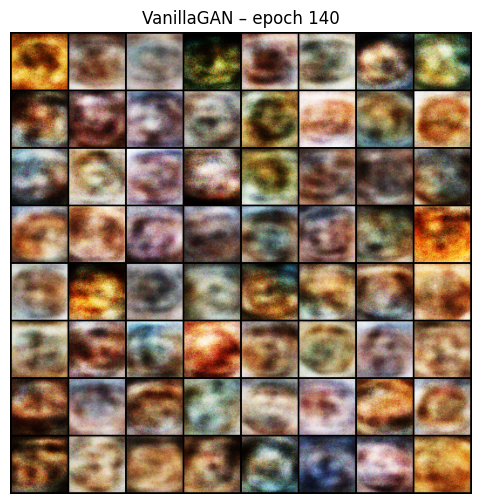

[VanillaGAN] Epoch 141 | D: 1.175 | G: 1.311 | D(x): 0.56 | D(G(z)): 0.36
[VanillaGAN] Epoch 142 | D: 1.173 | G: 1.415 | D(x): 0.56 | D(G(z)): 0.34
[VanillaGAN] Epoch 143 | D: 1.164 | G: 1.403 | D(x): 0.57 | D(G(z)): 0.34
[VanillaGAN] Epoch 144 | D: 1.183 | G: 1.344 | D(x): 0.55 | D(G(z)): 0.35
[VanillaGAN] Epoch 145 | D: 1.156 | G: 1.425 | D(x): 0.57 | D(G(z)): 0.34
[VanillaGAN] Epoch 146 | D: 1.165 | G: 1.339 | D(x): 0.57 | D(G(z)): 0.35
[VanillaGAN] Epoch 147 | D: 1.146 | G: 1.313 | D(x): 0.57 | D(G(z)): 0.34
[VanillaGAN] Epoch 148 | D: 1.146 | G: 1.373 | D(x): 0.58 | D(G(z)): 0.34
[VanillaGAN] Epoch 149 | D: 1.140 | G: 1.338 | D(x): 0.58 | D(G(z)): 0.34
[VanillaGAN] Epoch 150 | D: 1.137 | G: 1.327 | D(x): 0.59 | D(G(z)): 0.34
[VanillaGAN] Epoch 151 | D: 1.162 | G: 1.319 | D(x): 0.58 | D(G(z)): 0.35
[VanillaGAN] Epoch 152 | D: 1.144 | G: 1.332 | D(x): 0.58 | D(G(z)): 0.34
[VanillaGAN] Epoch 153 | D: 1.173 | G: 1.317 | D(x): 0.57 | D(G(z)): 0.35
[VanillaGAN] Epoch 154 | D: 1.159 | G:

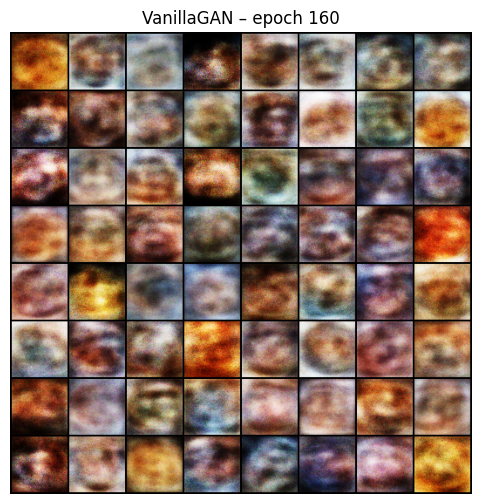

[VanillaGAN] Epoch 161 | D: 1.198 | G: 1.256 | D(x): 0.54 | D(G(z)): 0.36
[VanillaGAN] Epoch 162 | D: 1.177 | G: 1.339 | D(x): 0.56 | D(G(z)): 0.35
[VanillaGAN] Epoch 163 | D: 1.186 | G: 1.312 | D(x): 0.55 | D(G(z)): 0.35
[VanillaGAN] Epoch 164 | D: 1.180 | G: 1.313 | D(x): 0.56 | D(G(z)): 0.35
[VanillaGAN] Epoch 165 | D: 1.170 | G: 1.331 | D(x): 0.56 | D(G(z)): 0.35
[VanillaGAN] Epoch 166 | D: 1.189 | G: 1.262 | D(x): 0.55 | D(G(z)): 0.36
[VanillaGAN] Epoch 167 | D: 1.192 | G: 1.297 | D(x): 0.55 | D(G(z)): 0.36
[VanillaGAN] Epoch 168 | D: 1.210 | G: 1.281 | D(x): 0.55 | D(G(z)): 0.36
[VanillaGAN] Epoch 169 | D: 1.223 | G: 1.229 | D(x): 0.54 | D(G(z)): 0.37
[VanillaGAN] Epoch 170 | D: 1.170 | G: 1.308 | D(x): 0.56 | D(G(z)): 0.35
[VanillaGAN] Epoch 171 | D: 1.193 | G: 1.300 | D(x): 0.55 | D(G(z)): 0.35
[VanillaGAN] Epoch 172 | D: 1.195 | G: 1.292 | D(x): 0.55 | D(G(z)): 0.35
[VanillaGAN] Epoch 173 | D: 1.173 | G: 1.291 | D(x): 0.56 | D(G(z)): 0.35
[VanillaGAN] Epoch 174 | D: 1.182 | G:

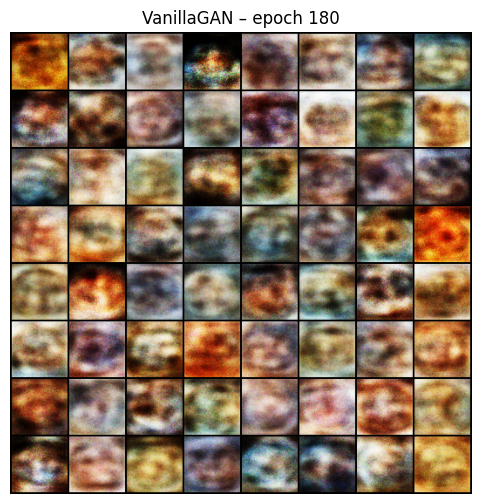

[VanillaGAN] Epoch 181 | D: 1.177 | G: 1.304 | D(x): 0.56 | D(G(z)): 0.35
[VanillaGAN] Epoch 182 | D: 1.159 | G: 1.351 | D(x): 0.57 | D(G(z)): 0.34
[VanillaGAN] Epoch 183 | D: 1.205 | G: 1.244 | D(x): 0.55 | D(G(z)): 0.36
[VanillaGAN] Epoch 184 | D: 1.169 | G: 1.348 | D(x): 0.56 | D(G(z)): 0.35
[VanillaGAN] Epoch 185 | D: 1.180 | G: 1.270 | D(x): 0.56 | D(G(z)): 0.35
[VanillaGAN] Epoch 186 | D: 1.187 | G: 1.262 | D(x): 0.56 | D(G(z)): 0.36
[VanillaGAN] Epoch 187 | D: 1.176 | G: 1.264 | D(x): 0.56 | D(G(z)): 0.36
[VanillaGAN] Epoch 188 | D: 1.178 | G: 1.288 | D(x): 0.56 | D(G(z)): 0.35
[VanillaGAN] Epoch 189 | D: 1.168 | G: 1.279 | D(x): 0.57 | D(G(z)): 0.35
[VanillaGAN] Epoch 190 | D: 1.183 | G: 1.264 | D(x): 0.56 | D(G(z)): 0.36
[VanillaGAN] Epoch 191 | D: 1.189 | G: 1.273 | D(x): 0.56 | D(G(z)): 0.36
[VanillaGAN] Epoch 192 | D: 1.189 | G: 1.241 | D(x): 0.56 | D(G(z)): 0.36
[VanillaGAN] Epoch 193 | D: 1.151 | G: 1.297 | D(x): 0.58 | D(G(z)): 0.35
[VanillaGAN] Epoch 194 | D: 1.218 | G:

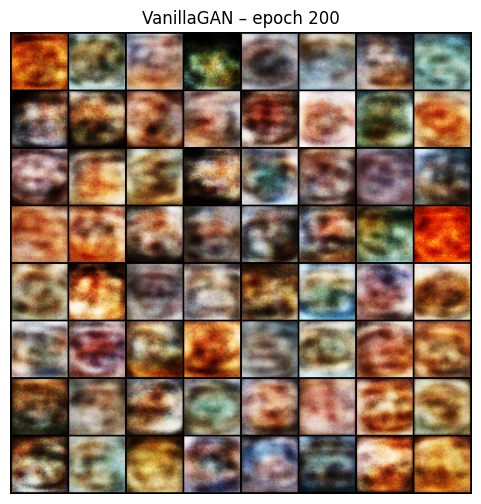

VanillaGAN: 200 epochs done, total training time 2.9 min


In [20]:
TRAIN_EPOCHS = 200

set_seed()
run_van = new_run(G_van, D_van, "VanillaGAN")
hist_van = train_epochs(run_van, TRAIN_EPOCHS, show_every=20)

[VanillaGAN] Epoch 201 | D: 1.167 | G: 1.255 | D(x): 0.57 | D(G(z)): 0.36
[VanillaGAN] Epoch 202 | D: 1.195 | G: 1.275 | D(x): 0.55 | D(G(z)): 0.36
[VanillaGAN] Epoch 203 | D: 1.194 | G: 1.245 | D(x): 0.56 | D(G(z)): 0.36
[VanillaGAN] Epoch 204 | D: 1.197 | G: 1.222 | D(x): 0.55 | D(G(z)): 0.37
[VanillaGAN] Epoch 205 | D: 1.192 | G: 1.229 | D(x): 0.56 | D(G(z)): 0.36
[VanillaGAN] Epoch 206 | D: 1.210 | G: 1.204 | D(x): 0.55 | D(G(z)): 0.37
[VanillaGAN] Epoch 207 | D: 1.176 | G: 1.292 | D(x): 0.56 | D(G(z)): 0.35
[VanillaGAN] Epoch 208 | D: 1.222 | G: 1.217 | D(x): 0.55 | D(G(z)): 0.37
[VanillaGAN] Epoch 209 | D: 1.200 | G: 1.214 | D(x): 0.55 | D(G(z)): 0.37
[VanillaGAN] Epoch 210 | D: 1.215 | G: 1.226 | D(x): 0.54 | D(G(z)): 0.36
[VanillaGAN] Epoch 211 | D: 1.213 | G: 1.272 | D(x): 0.54 | D(G(z)): 0.36
[VanillaGAN] Epoch 212 | D: 1.257 | G: 1.182 | D(x): 0.52 | D(G(z)): 0.38
[VanillaGAN] Epoch 213 | D: 1.191 | G: 1.208 | D(x): 0.55 | D(G(z)): 0.36
[VanillaGAN] Epoch 214 | D: 1.199 | G:

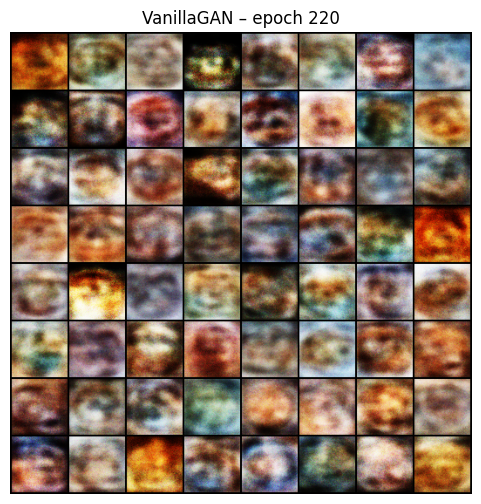

[VanillaGAN] Epoch 221 | D: 1.199 | G: 1.243 | D(x): 0.54 | D(G(z)): 0.36
[VanillaGAN] Epoch 222 | D: 1.194 | G: 1.282 | D(x): 0.55 | D(G(z)): 0.36
[VanillaGAN] Epoch 223 | D: 1.198 | G: 1.229 | D(x): 0.54 | D(G(z)): 0.36
[VanillaGAN] Epoch 224 | D: 1.190 | G: 1.236 | D(x): 0.55 | D(G(z)): 0.36
[VanillaGAN] Epoch 225 | D: 1.184 | G: 1.258 | D(x): 0.56 | D(G(z)): 0.36
[VanillaGAN] Epoch 226 | D: 1.181 | G: 1.233 | D(x): 0.56 | D(G(z)): 0.36
[VanillaGAN] Epoch 227 | D: 1.197 | G: 1.247 | D(x): 0.56 | D(G(z)): 0.36
[VanillaGAN] Epoch 228 | D: 1.172 | G: 1.254 | D(x): 0.56 | D(G(z)): 0.36
[VanillaGAN] Epoch 229 | D: 1.187 | G: 1.237 | D(x): 0.56 | D(G(z)): 0.36
[VanillaGAN] Epoch 230 | D: 1.212 | G: 1.219 | D(x): 0.55 | D(G(z)): 0.37
[VanillaGAN] Epoch 231 | D: 1.208 | G: 1.202 | D(x): 0.55 | D(G(z)): 0.37
[VanillaGAN] Epoch 232 | D: 1.196 | G: 1.218 | D(x): 0.55 | D(G(z)): 0.37
[VanillaGAN] Epoch 233 | D: 1.229 | G: 1.179 | D(x): 0.54 | D(G(z)): 0.38
[VanillaGAN] Epoch 234 | D: 1.218 | G:

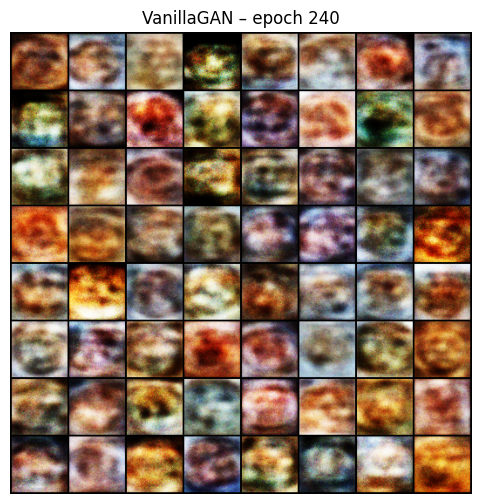

[VanillaGAN] Epoch 241 | D: 1.199 | G: 1.270 | D(x): 0.54 | D(G(z)): 0.36
[VanillaGAN] Epoch 242 | D: 1.234 | G: 1.243 | D(x): 0.53 | D(G(z)): 0.37
[VanillaGAN] Epoch 243 | D: 1.211 | G: 1.225 | D(x): 0.54 | D(G(z)): 0.37
[VanillaGAN] Epoch 244 | D: 1.210 | G: 1.236 | D(x): 0.54 | D(G(z)): 0.37
[VanillaGAN] Epoch 245 | D: 1.213 | G: 1.215 | D(x): 0.54 | D(G(z)): 0.37
[VanillaGAN] Epoch 246 | D: 1.197 | G: 1.199 | D(x): 0.55 | D(G(z)): 0.37
[VanillaGAN] Epoch 247 | D: 1.219 | G: 1.199 | D(x): 0.54 | D(G(z)): 0.37
[VanillaGAN] Epoch 248 | D: 1.230 | G: 1.183 | D(x): 0.53 | D(G(z)): 0.37
[VanillaGAN] Epoch 249 | D: 1.212 | G: 1.156 | D(x): 0.54 | D(G(z)): 0.38
[VanillaGAN] Epoch 250 | D: 1.243 | G: 1.150 | D(x): 0.53 | D(G(z)): 0.38
[VanillaGAN] Epoch 251 | D: 1.232 | G: 1.181 | D(x): 0.53 | D(G(z)): 0.38
[VanillaGAN] Epoch 252 | D: 1.234 | G: 1.125 | D(x): 0.53 | D(G(z)): 0.38
[VanillaGAN] Epoch 253 | D: 1.220 | G: 1.177 | D(x): 0.54 | D(G(z)): 0.38
[VanillaGAN] Epoch 254 | D: 1.210 | G:

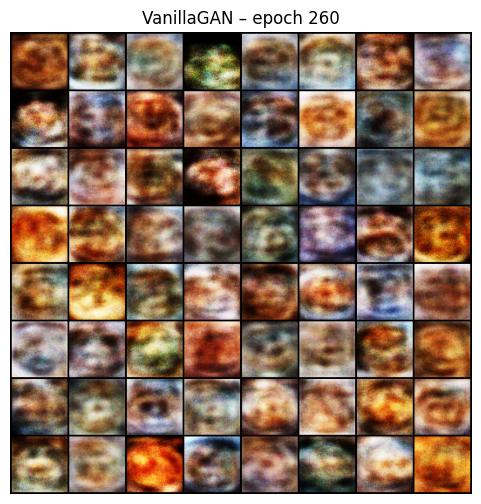

[VanillaGAN] Epoch 261 | D: 1.209 | G: 1.187 | D(x): 0.54 | D(G(z)): 0.37
[VanillaGAN] Epoch 262 | D: 1.205 | G: 1.212 | D(x): 0.54 | D(G(z)): 0.37
[VanillaGAN] Epoch 263 | D: 1.230 | G: 1.188 | D(x): 0.54 | D(G(z)): 0.38
[VanillaGAN] Epoch 264 | D: 1.242 | G: 1.154 | D(x): 0.53 | D(G(z)): 0.38
[VanillaGAN] Epoch 265 | D: 1.228 | G: 1.178 | D(x): 0.53 | D(G(z)): 0.37
[VanillaGAN] Epoch 266 | D: 1.242 | G: 1.148 | D(x): 0.53 | D(G(z)): 0.38
[VanillaGAN] Epoch 267 | D: 1.242 | G: 1.160 | D(x): 0.53 | D(G(z)): 0.38
[VanillaGAN] Epoch 268 | D: 1.247 | G: 1.139 | D(x): 0.52 | D(G(z)): 0.38
[VanillaGAN] Epoch 269 | D: 1.217 | G: 1.192 | D(x): 0.54 | D(G(z)): 0.37
[VanillaGAN] Epoch 270 | D: 1.233 | G: 1.192 | D(x): 0.53 | D(G(z)): 0.37
[VanillaGAN] Epoch 271 | D: 1.254 | G: 1.159 | D(x): 0.52 | D(G(z)): 0.38
[VanillaGAN] Epoch 272 | D: 1.210 | G: 1.155 | D(x): 0.54 | D(G(z)): 0.37
[VanillaGAN] Epoch 273 | D: 1.207 | G: 1.203 | D(x): 0.54 | D(G(z)): 0.37
[VanillaGAN] Epoch 274 | D: 1.226 | G:

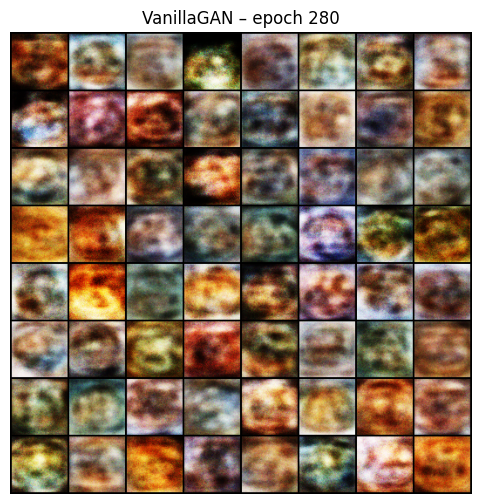

[VanillaGAN] Epoch 281 | D: 1.238 | G: 1.176 | D(x): 0.53 | D(G(z)): 0.38
[VanillaGAN] Epoch 282 | D: 1.228 | G: 1.177 | D(x): 0.53 | D(G(z)): 0.37
[VanillaGAN] Epoch 283 | D: 1.235 | G: 1.147 | D(x): 0.53 | D(G(z)): 0.38
[VanillaGAN] Epoch 284 | D: 1.228 | G: 1.188 | D(x): 0.53 | D(G(z)): 0.37
[VanillaGAN] Epoch 285 | D: 1.236 | G: 1.191 | D(x): 0.53 | D(G(z)): 0.37
[VanillaGAN] Epoch 286 | D: 1.247 | G: 1.138 | D(x): 0.52 | D(G(z)): 0.38
[VanillaGAN] Epoch 287 | D: 1.229 | G: 1.170 | D(x): 0.53 | D(G(z)): 0.38
[VanillaGAN] Epoch 288 | D: 1.231 | G: 1.186 | D(x): 0.53 | D(G(z)): 0.37
[VanillaGAN] Epoch 289 | D: 1.247 | G: 1.138 | D(x): 0.52 | D(G(z)): 0.38
[VanillaGAN] Epoch 290 | D: 1.241 | G: 1.157 | D(x): 0.52 | D(G(z)): 0.38
[VanillaGAN] Epoch 291 | D: 1.242 | G: 1.097 | D(x): 0.53 | D(G(z)): 0.39
[VanillaGAN] Epoch 292 | D: 1.236 | G: 1.132 | D(x): 0.53 | D(G(z)): 0.38
[VanillaGAN] Epoch 293 | D: 1.228 | G: 1.158 | D(x): 0.53 | D(G(z)): 0.37
[VanillaGAN] Epoch 294 | D: 1.235 | G:

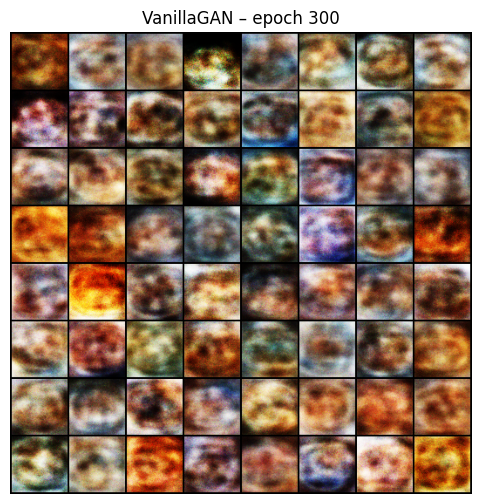

VanillaGAN: 300 epochs done, total training time 4.4 min


In [21]:
hist_van = train_epochs(run_van, 100, show_every=20)   # adds 100 more epochs

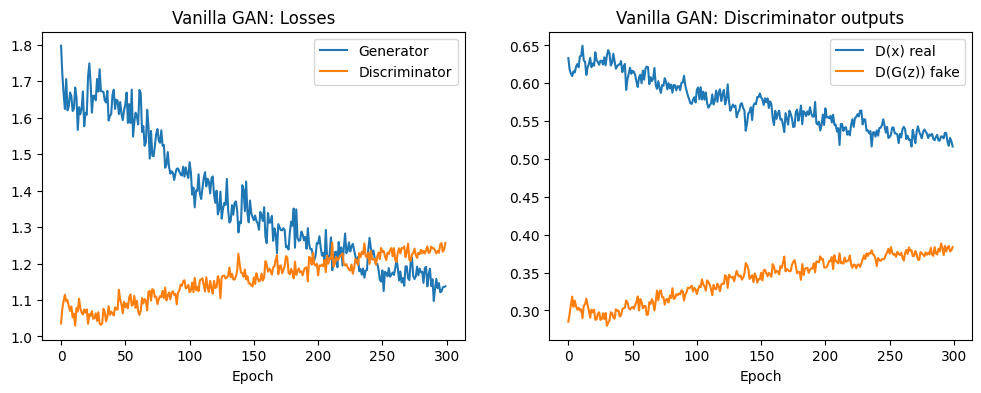

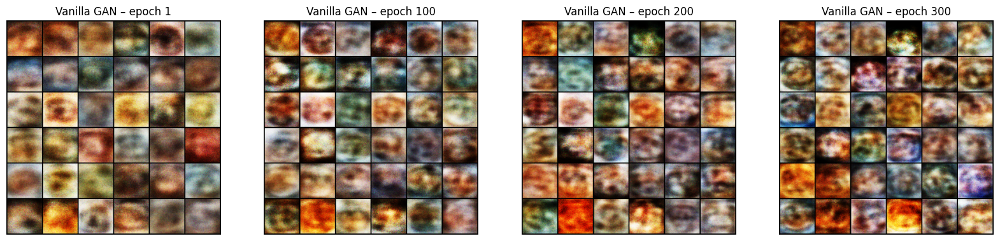

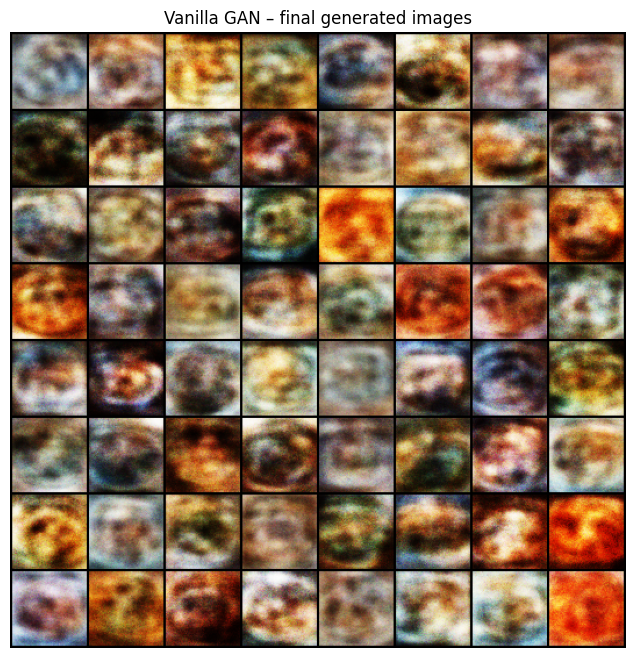

In [22]:
plot_history(hist_van, "Vanilla GAN")
show_progress(hist_van, "Vanilla GAN")

G_van.eval()
with torch.no_grad():
    samples_van = G_van(torch.randn(64, NZ, device=device)).cpu()
show_grid(samples_van, "Vanilla GAN – final generated images")
torch.save(G_van.state_dict(), "vanilla_G.pth")

In [23]:
TRAIN_EPOCHS = 300

missing = TRAIN_EPOCHS - run_van["epoch"]
if missing > 0:
    hist_van = train_epochs(run_van, missing, show_every=50)
print("Vanilla GAN epochs trained:", run_van["epoch"])

Vanilla GAN epochs trained: 300


In [24]:
def weights_init(m):
    cn = m.__class__.__name__
    if "Conv" in cn:
        nn.init.normal_(m.weight, 0.0, 0.02)
    elif "BatchNorm" in cn:
        nn.init.normal_(m.weight, 1.0, 0.02); nn.init.zeros_(m.bias)

class DCG(nn.Module):
    def __init__(self, nz=NZ, ngf=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(nz, ngf*8, 4, 1, 0, bias=False), nn.BatchNorm2d(ngf*8), nn.ReLU(True),    # 512x4x4
            nn.ConvTranspose2d(ngf*8, ngf*4, 4, 2, 1, bias=False), nn.BatchNorm2d(ngf*4), nn.ReLU(True),  # 256x8x8
            nn.ConvTranspose2d(ngf*4, ngf*2, 4, 2, 1, bias=False), nn.BatchNorm2d(ngf*2), nn.ReLU(True),  # 128x16x16
            nn.ConvTranspose2d(ngf*2, ngf, 4, 2, 1, bias=False), nn.BatchNorm2d(ngf), nn.ReLU(True),      # 64x32x32
            nn.ConvTranspose2d(ngf, 3, 4, 2, 1, bias=False), nn.Tanh()                                    # 3x64x64
        )
    def forward(self, z):
        return self.net(z.view(z.size(0), -1, 1, 1))

class DCD(nn.Module):
    def __init__(self, ndf=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, ndf, 4, 2, 1, bias=False), nn.LeakyReLU(0.2, True),                               # 64x32x32
            nn.Conv2d(ndf, ndf*2, 4, 2, 1, bias=False), nn.BatchNorm2d(ndf*2), nn.LeakyReLU(0.2, True),    # 128x16x16
            nn.Conv2d(ndf*2, ndf*4, 4, 2, 1, bias=False), nn.BatchNorm2d(ndf*4), nn.LeakyReLU(0.2, True),  # 256x8x8
            nn.Conv2d(ndf*4, ndf*8, 4, 2, 1, bias=False), nn.BatchNorm2d(ndf*8), nn.LeakyReLU(0.2, True),  # 512x4x4
            nn.Conv2d(ndf*8, 1, 4, 1, 0, bias=False)                                                       # 1x1x1 logit
        )
    def forward(self, x):
        return self.net(x).view(-1)

set_seed()
G_dc, D_dc = DCG(), DCD()
G_dc.apply(weights_init); D_dc.apply(weights_init)
print(G_dc); print(D_dc)
print(f"DCGAN G params: {count_params(G_dc):,} | D params: {count_params(D_dc):,}")

DCG(
  (net): Sequential(
    (0): ConvTranspose2d(100, 512, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(512, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU(inplace=True)
    (9): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (10): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): ReLU(inplace=True)
    (12): ConvTranspose2d(64, 3, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (13): Tanh()
  )
)
DCD(
  

[DCGAN] Epoch   1 | D: 1.343 | G: 11.251 | D(x): 0.66 | D(G(z)): 0.31
[DCGAN] Epoch   2 | D: 1.048 | G: 7.419 | D(x): 0.68 | D(G(z)): 0.22
[DCGAN] Epoch   3 | D: 0.853 | G: 4.548 | D(x): 0.70 | D(G(z)): 0.19
[DCGAN] Epoch   4 | D: 0.741 | G: 5.144 | D(x): 0.75 | D(G(z)): 0.15
[DCGAN] Epoch   5 | D: 0.656 | G: 5.468 | D(x): 0.78 | D(G(z)): 0.12
[DCGAN] Epoch   6 | D: 0.598 | G: 4.815 | D(x): 0.80 | D(G(z)): 0.10
[DCGAN] Epoch   7 | D: 0.905 | G: 3.649 | D(x): 0.69 | D(G(z)): 0.20
[DCGAN] Epoch   8 | D: 1.090 | G: 3.063 | D(x): 0.62 | D(G(z)): 0.28
[DCGAN] Epoch   9 | D: 0.921 | G: 3.489 | D(x): 0.67 | D(G(z)): 0.22
[DCGAN] Epoch  10 | D: 0.945 | G: 3.838 | D(x): 0.66 | D(G(z)): 0.23
[DCGAN] Epoch  11 | D: 0.725 | G: 3.730 | D(x): 0.72 | D(G(z)): 0.17
[DCGAN] Epoch  12 | D: 0.823 | G: 3.912 | D(x): 0.70 | D(G(z)): 0.19
[DCGAN] Epoch  13 | D: 0.832 | G: 4.211 | D(x): 0.71 | D(G(z)): 0.19
[DCGAN] Epoch  14 | D: 0.644 | G: 4.290 | D(x): 0.75 | D(G(z)): 0.14
[DCGAN] Epoch  15 | D: 0.828 | G:

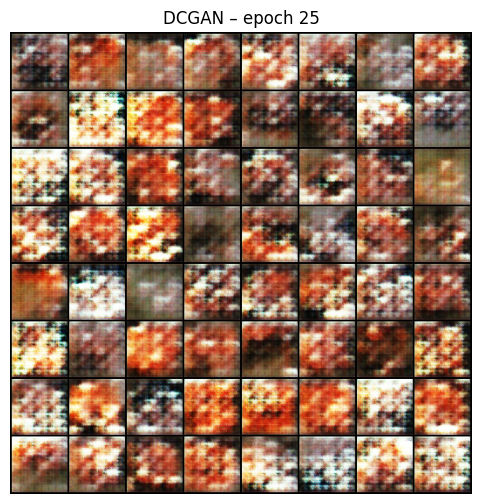

[DCGAN] Epoch  26 | D: 0.789 | G: 4.311 | D(x): 0.74 | D(G(z)): 0.17
[DCGAN] Epoch  27 | D: 0.967 | G: 4.330 | D(x): 0.66 | D(G(z)): 0.23
[DCGAN] Epoch  28 | D: 0.803 | G: 3.754 | D(x): 0.70 | D(G(z)): 0.19
[DCGAN] Epoch  29 | D: 0.690 | G: 3.980 | D(x): 0.74 | D(G(z)): 0.15
[DCGAN] Epoch  30 | D: 0.761 | G: 4.182 | D(x): 0.73 | D(G(z)): 0.17
[DCGAN] Epoch  31 | D: 0.726 | G: 3.900 | D(x): 0.74 | D(G(z)): 0.16
[DCGAN] Epoch  32 | D: 0.731 | G: 4.230 | D(x): 0.73 | D(G(z)): 0.16
[DCGAN] Epoch  33 | D: 0.712 | G: 4.209 | D(x): 0.75 | D(G(z)): 0.14
[DCGAN] Epoch  34 | D: 0.699 | G: 4.102 | D(x): 0.74 | D(G(z)): 0.15
[DCGAN] Epoch  35 | D: 0.736 | G: 4.374 | D(x): 0.74 | D(G(z)): 0.16
[DCGAN] Epoch  36 | D: 0.783 | G: 4.111 | D(x): 0.72 | D(G(z)): 0.17
[DCGAN] Epoch  37 | D: 0.745 | G: 4.071 | D(x): 0.73 | D(G(z)): 0.17
[DCGAN] Epoch  38 | D: 0.877 | G: 4.032 | D(x): 0.70 | D(G(z)): 0.19
[DCGAN] Epoch  39 | D: 0.797 | G: 3.704 | D(x): 0.71 | D(G(z)): 0.18
[DCGAN] Epoch  40 | D: 0.800 | G: 

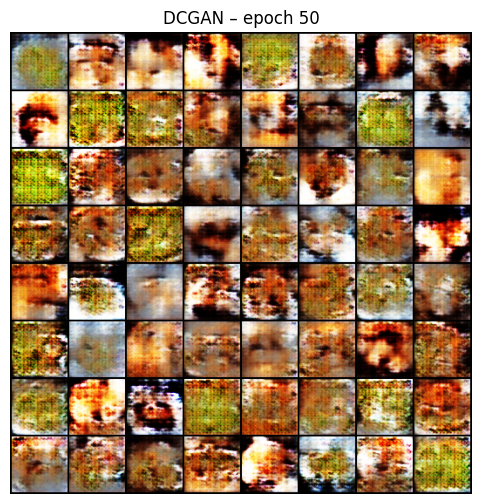

[DCGAN] Epoch  51 | D: 0.754 | G: 4.073 | D(x): 0.74 | D(G(z)): 0.17
[DCGAN] Epoch  52 | D: 0.653 | G: 3.799 | D(x): 0.75 | D(G(z)): 0.14
[DCGAN] Epoch  53 | D: 0.875 | G: 3.749 | D(x): 0.73 | D(G(z)): 0.17
[DCGAN] Epoch  54 | D: 0.794 | G: 3.711 | D(x): 0.71 | D(G(z)): 0.18
[DCGAN] Epoch  55 | D: 0.623 | G: 3.693 | D(x): 0.75 | D(G(z)): 0.14
[DCGAN] Epoch  56 | D: 0.619 | G: 3.651 | D(x): 0.77 | D(G(z)): 0.14
[DCGAN] Epoch  57 | D: 0.836 | G: 3.896 | D(x): 0.71 | D(G(z)): 0.18
[DCGAN] Epoch  58 | D: 0.625 | G: 3.640 | D(x): 0.76 | D(G(z)): 0.14
[DCGAN] Epoch  59 | D: 0.847 | G: 3.673 | D(x): 0.74 | D(G(z)): 0.16
[DCGAN] Epoch  60 | D: 0.758 | G: 3.322 | D(x): 0.71 | D(G(z)): 0.18
[DCGAN] Epoch  61 | D: 0.613 | G: 3.574 | D(x): 0.76 | D(G(z)): 0.13
[DCGAN] Epoch  62 | D: 0.655 | G: 3.788 | D(x): 0.76 | D(G(z)): 0.14
[DCGAN] Epoch  63 | D: 0.691 | G: 3.613 | D(x): 0.75 | D(G(z)): 0.15
[DCGAN] Epoch  64 | D: 0.570 | G: 3.797 | D(x): 0.78 | D(G(z)): 0.12
[DCGAN] Epoch  65 | D: 0.644 | G: 

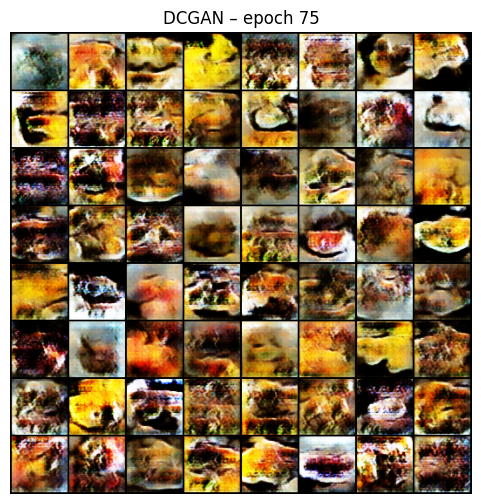

[DCGAN] Epoch  76 | D: 0.648 | G: 3.351 | D(x): 0.75 | D(G(z)): 0.15
[DCGAN] Epoch  77 | D: 0.606 | G: 3.269 | D(x): 0.76 | D(G(z)): 0.13
[DCGAN] Epoch  78 | D: 0.865 | G: 3.133 | D(x): 0.72 | D(G(z)): 0.18
[DCGAN] Epoch  79 | D: 0.594 | G: 3.239 | D(x): 0.76 | D(G(z)): 0.13
[DCGAN] Epoch  80 | D: 0.607 | G: 3.219 | D(x): 0.76 | D(G(z)): 0.13
[DCGAN] Epoch  81 | D: 0.600 | G: 3.415 | D(x): 0.77 | D(G(z)): 0.13
[DCGAN] Epoch  82 | D: 0.983 | G: 3.728 | D(x): 0.69 | D(G(z)): 0.21
[DCGAN] Epoch  83 | D: 0.616 | G: 3.138 | D(x): 0.75 | D(G(z)): 0.13
[DCGAN] Epoch  84 | D: 0.604 | G: 3.270 | D(x): 0.76 | D(G(z)): 0.13
[DCGAN] Epoch  85 | D: 0.950 | G: 3.662 | D(x): 0.71 | D(G(z)): 0.20
[DCGAN] Epoch  86 | D: 0.667 | G: 3.150 | D(x): 0.74 | D(G(z)): 0.16
[DCGAN] Epoch  87 | D: 0.586 | G: 3.170 | D(x): 0.77 | D(G(z)): 0.13
[DCGAN] Epoch  88 | D: 0.826 | G: 3.515 | D(x): 0.72 | D(G(z)): 0.18
[DCGAN] Epoch  89 | D: 0.596 | G: 3.187 | D(x): 0.77 | D(G(z)): 0.14
[DCGAN] Epoch  90 | D: 0.776 | G: 

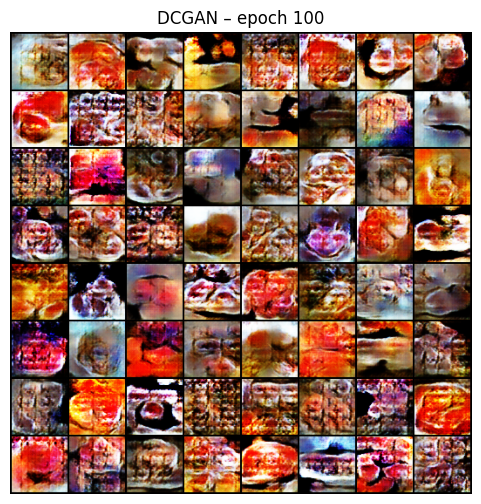

[DCGAN] Epoch 101 | D: 0.662 | G: 3.494 | D(x): 0.75 | D(G(z)): 0.15
[DCGAN] Epoch 102 | D: 0.709 | G: 3.358 | D(x): 0.74 | D(G(z)): 0.17
[DCGAN] Epoch 103 | D: 0.867 | G: 3.221 | D(x): 0.70 | D(G(z)): 0.20
[DCGAN] Epoch 104 | D: 0.620 | G: 3.111 | D(x): 0.76 | D(G(z)): 0.15
[DCGAN] Epoch 105 | D: 1.132 | G: 3.237 | D(x): 0.68 | D(G(z)): 0.22
[DCGAN] Epoch 106 | D: 0.720 | G: 2.962 | D(x): 0.71 | D(G(z)): 0.18
[DCGAN] Epoch 107 | D: 0.606 | G: 2.933 | D(x): 0.76 | D(G(z)): 0.14
[DCGAN] Epoch 108 | D: 0.697 | G: 3.140 | D(x): 0.73 | D(G(z)): 0.16
[DCGAN] Epoch 109 | D: 0.826 | G: 3.296 | D(x): 0.72 | D(G(z)): 0.19
[DCGAN] Epoch 110 | D: 0.755 | G: 3.089 | D(x): 0.71 | D(G(z)): 0.18
[DCGAN] Epoch 111 | D: 0.609 | G: 3.021 | D(x): 0.75 | D(G(z)): 0.14
[DCGAN] Epoch 112 | D: 0.601 | G: 3.026 | D(x): 0.76 | D(G(z)): 0.13
[DCGAN] Epoch 113 | D: 0.845 | G: 3.311 | D(x): 0.73 | D(G(z)): 0.18
[DCGAN] Epoch 114 | D: 0.811 | G: 3.318 | D(x): 0.70 | D(G(z)): 0.19
[DCGAN] Epoch 115 | D: 0.605 | G: 

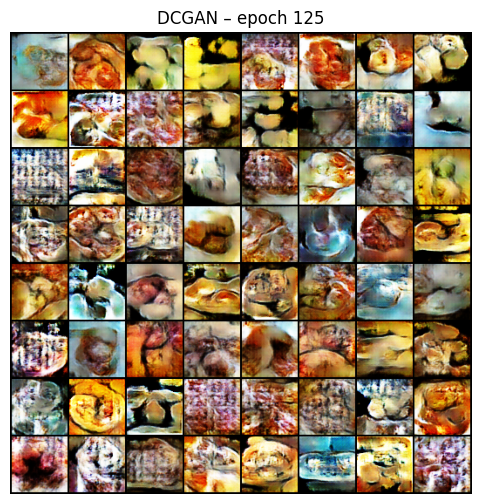

[DCGAN] Epoch 126 | D: 0.631 | G: 3.177 | D(x): 0.76 | D(G(z)): 0.14
[DCGAN] Epoch 127 | D: 0.877 | G: 3.262 | D(x): 0.72 | D(G(z)): 0.18
[DCGAN] Epoch 128 | D: 0.652 | G: 3.030 | D(x): 0.74 | D(G(z)): 0.16
[DCGAN] Epoch 129 | D: 0.609 | G: 3.042 | D(x): 0.76 | D(G(z)): 0.14
[DCGAN] Epoch 130 | D: 0.718 | G: 3.118 | D(x): 0.73 | D(G(z)): 0.16
[DCGAN] Epoch 131 | D: 0.605 | G: 3.137 | D(x): 0.77 | D(G(z)): 0.14
[DCGAN] Epoch 132 | D: 0.869 | G: 3.206 | D(x): 0.70 | D(G(z)): 0.20
[DCGAN] Epoch 133 | D: 0.588 | G: 2.990 | D(x): 0.76 | D(G(z)): 0.13
[DCGAN] Epoch 134 | D: 0.568 | G: 2.975 | D(x): 0.78 | D(G(z)): 0.12
[DCGAN] Epoch 135 | D: 0.833 | G: 3.172 | D(x): 0.72 | D(G(z)): 0.18
[DCGAN] Epoch 136 | D: 0.587 | G: 3.035 | D(x): 0.77 | D(G(z)): 0.13
[DCGAN] Epoch 137 | D: 0.923 | G: 3.234 | D(x): 0.71 | D(G(z)): 0.19
[DCGAN] Epoch 138 | D: 0.591 | G: 2.993 | D(x): 0.76 | D(G(z)): 0.14
[DCGAN] Epoch 139 | D: 0.560 | G: 3.025 | D(x): 0.78 | D(G(z)): 0.12
[DCGAN] Epoch 140 | D: 1.013 | G: 

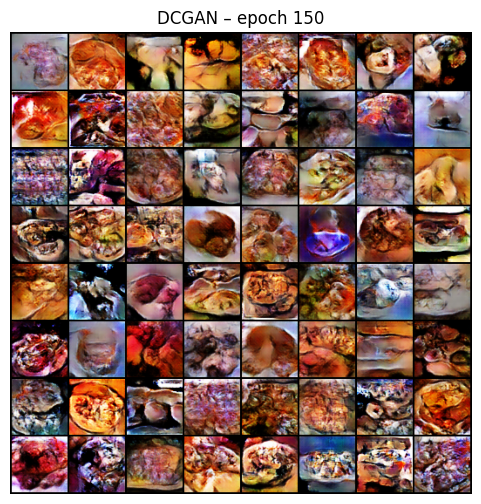

[DCGAN] Epoch 151 | D: 0.541 | G: 3.046 | D(x): 0.79 | D(G(z)): 0.11
[DCGAN] Epoch 152 | D: 0.682 | G: 3.193 | D(x): 0.75 | D(G(z)): 0.14
[DCGAN] Epoch 153 | D: 0.873 | G: 3.197 | D(x): 0.72 | D(G(z)): 0.19
[DCGAN] Epoch 154 | D: 0.599 | G: 3.124 | D(x): 0.77 | D(G(z)): 0.13
[DCGAN] Epoch 155 | D: 0.551 | G: 3.163 | D(x): 0.78 | D(G(z)): 0.12
[DCGAN] Epoch 156 | D: 0.811 | G: 3.359 | D(x): 0.72 | D(G(z)): 0.18
[DCGAN] Epoch 157 | D: 0.559 | G: 3.125 | D(x): 0.78 | D(G(z)): 0.12
[DCGAN] Epoch 158 | D: 0.550 | G: 3.153 | D(x): 0.79 | D(G(z)): 0.11
[DCGAN] Epoch 159 | D: 0.520 | G: 3.224 | D(x): 0.80 | D(G(z)): 0.10
[DCGAN] Epoch 160 | D: 1.222 | G: 3.664 | D(x): 0.74 | D(G(z)): 0.17
[DCGAN] Epoch 161 | D: 0.962 | G: 3.014 | D(x): 0.66 | D(G(z)): 0.23
[DCGAN] Epoch 162 | D: 0.622 | G: 3.070 | D(x): 0.76 | D(G(z)): 0.15
[DCGAN] Epoch 163 | D: 0.590 | G: 2.928 | D(x): 0.77 | D(G(z)): 0.12
[DCGAN] Epoch 164 | D: 0.994 | G: 3.083 | D(x): 0.69 | D(G(z)): 0.22
[DCGAN] Epoch 165 | D: 0.552 | G: 

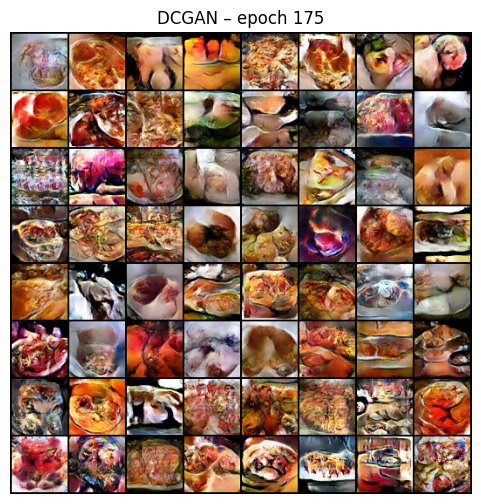

[DCGAN] Epoch 176 | D: 0.519 | G: 3.169 | D(x): 0.80 | D(G(z)): 0.10
[DCGAN] Epoch 177 | D: 0.560 | G: 3.278 | D(x): 0.79 | D(G(z)): 0.11
[DCGAN] Epoch 178 | D: 0.503 | G: 3.303 | D(x): 0.81 | D(G(z)): 0.09
[DCGAN] Epoch 179 | D: 1.061 | G: 3.516 | D(x): 0.70 | D(G(z)): 0.21
[DCGAN] Epoch 180 | D: 0.592 | G: 3.129 | D(x): 0.77 | D(G(z)): 0.13
[DCGAN] Epoch 181 | D: 0.523 | G: 3.203 | D(x): 0.80 | D(G(z)): 0.11
[DCGAN] Epoch 182 | D: 0.510 | G: 3.200 | D(x): 0.80 | D(G(z)): 0.10
[DCGAN] Epoch 183 | D: 0.489 | G: 3.256 | D(x): 0.81 | D(G(z)): 0.09
[DCGAN] Epoch 184 | D: 0.543 | G: 3.349 | D(x): 0.79 | D(G(z)): 0.10
[DCGAN] Epoch 185 | D: 1.110 | G: 3.450 | D(x): 0.68 | D(G(z)): 0.23
[DCGAN] Epoch 186 | D: 0.532 | G: 3.191 | D(x): 0.79 | D(G(z)): 0.11
[DCGAN] Epoch 187 | D: 0.509 | G: 3.208 | D(x): 0.80 | D(G(z)): 0.09
[DCGAN] Epoch 188 | D: 0.548 | G: 3.287 | D(x): 0.80 | D(G(z)): 0.11
[DCGAN] Epoch 189 | D: 0.515 | G: 3.299 | D(x): 0.80 | D(G(z)): 0.09
[DCGAN] Epoch 190 | D: 0.529 | G: 

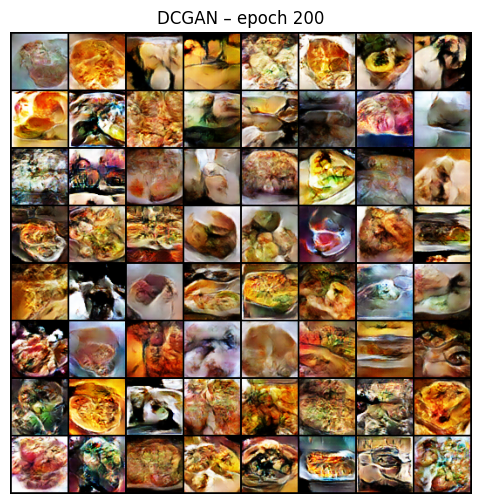

[DCGAN] Epoch 201 | D: 0.513 | G: 3.425 | D(x): 0.81 | D(G(z)): 0.09
[DCGAN] Epoch 202 | D: 0.486 | G: 3.427 | D(x): 0.82 | D(G(z)): 0.08
[DCGAN] Epoch 203 | D: 1.156 | G: 3.803 | D(x): 0.70 | D(G(z)): 0.19
[DCGAN] Epoch 204 | D: 0.713 | G: 3.230 | D(x): 0.74 | D(G(z)): 0.17
[DCGAN] Epoch 205 | D: 0.515 | G: 3.233 | D(x): 0.80 | D(G(z)): 0.10
[DCGAN] Epoch 206 | D: 0.489 | G: 3.241 | D(x): 0.81 | D(G(z)): 0.09
[DCGAN] Epoch 207 | D: 0.475 | G: 3.346 | D(x): 0.82 | D(G(z)): 0.08
[DCGAN] Epoch 208 | D: 0.466 | G: 3.398 | D(x): 0.82 | D(G(z)): 0.08
[DCGAN] Epoch 209 | D: 0.484 | G: 3.440 | D(x): 0.82 | D(G(z)): 0.08
[DCGAN] Epoch 210 | D: 0.494 | G: 3.501 | D(x): 0.82 | D(G(z)): 0.08
[DCGAN] Epoch 211 | D: 0.559 | G: 3.499 | D(x): 0.80 | D(G(z)): 0.10
[DCGAN] Epoch 212 | D: 0.531 | G: 3.507 | D(x): 0.81 | D(G(z)): 0.10
[DCGAN] Epoch 213 | D: 0.470 | G: 3.531 | D(x): 0.83 | D(G(z)): 0.08
[DCGAN] Epoch 214 | D: 0.472 | G: 3.563 | D(x): 0.82 | D(G(z)): 0.07
[DCGAN] Epoch 215 | D: 0.454 | G: 

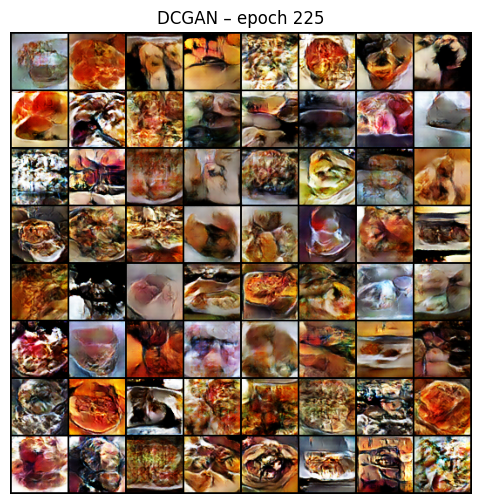

[DCGAN] Epoch 226 | D: 0.515 | G: 3.396 | D(x): 0.81 | D(G(z)): 0.09
[DCGAN] Epoch 227 | D: 0.486 | G: 3.356 | D(x): 0.82 | D(G(z)): 0.08
[DCGAN] Epoch 228 | D: 0.458 | G: 3.488 | D(x): 0.83 | D(G(z)): 0.07
[DCGAN] Epoch 229 | D: 0.451 | G: 3.512 | D(x): 0.83 | D(G(z)): 0.07
[DCGAN] Epoch 230 | D: 0.463 | G: 3.550 | D(x): 0.83 | D(G(z)): 0.07
[DCGAN] Epoch 231 | D: 0.430 | G: 3.580 | D(x): 0.84 | D(G(z)): 0.06
[DCGAN] Epoch 232 | D: 0.442 | G: 3.589 | D(x): 0.84 | D(G(z)): 0.06
[DCGAN] Epoch 233 | D: 0.427 | G: 3.659 | D(x): 0.84 | D(G(z)): 0.05
[DCGAN] Epoch 234 | D: 0.447 | G: 3.695 | D(x): 0.84 | D(G(z)): 0.06
[DCGAN] Epoch 235 | D: 0.532 | G: 3.736 | D(x): 0.81 | D(G(z)): 0.08
[DCGAN] Epoch 236 | D: 1.898 | G: 3.550 | D(x): 0.61 | D(G(z)): 0.30
[DCGAN] Epoch 237 | D: 0.590 | G: 3.157 | D(x): 0.77 | D(G(z)): 0.13
[DCGAN] Epoch 238 | D: 0.494 | G: 3.224 | D(x): 0.81 | D(G(z)): 0.09
[DCGAN] Epoch 239 | D: 0.461 | G: 3.310 | D(x): 0.82 | D(G(z)): 0.08
[DCGAN] Epoch 240 | D: 0.453 | G: 

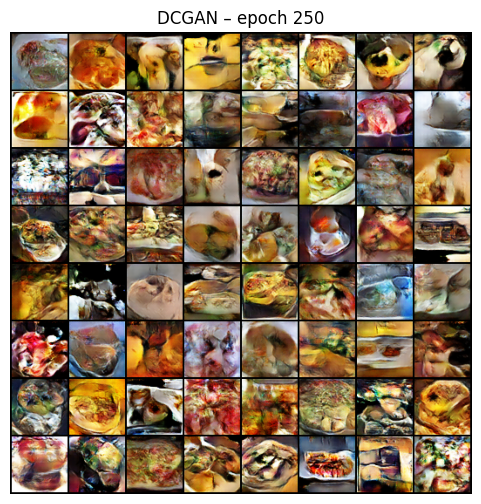

[DCGAN] Epoch 251 | D: 0.442 | G: 3.510 | D(x): 0.84 | D(G(z)): 0.06
[DCGAN] Epoch 252 | D: 0.423 | G: 3.585 | D(x): 0.84 | D(G(z)): 0.06
[DCGAN] Epoch 253 | D: 0.447 | G: 3.600 | D(x): 0.84 | D(G(z)): 0.06
[DCGAN] Epoch 254 | D: 0.436 | G: 3.670 | D(x): 0.84 | D(G(z)): 0.06
[DCGAN] Epoch 255 | D: 0.428 | G: 3.702 | D(x): 0.84 | D(G(z)): 0.05
[DCGAN] Epoch 256 | D: 0.438 | G: 3.711 | D(x): 0.84 | D(G(z)): 0.06
[DCGAN] Epoch 257 | D: 0.433 | G: 3.696 | D(x): 0.84 | D(G(z)): 0.05
[DCGAN] Epoch 258 | D: 0.426 | G: 3.841 | D(x): 0.85 | D(G(z)): 0.05
[DCGAN] Epoch 259 | D: 0.936 | G: 4.070 | D(x): 0.80 | D(G(z)): 0.11
[DCGAN] Epoch 260 | D: 1.128 | G: 3.220 | D(x): 0.69 | D(G(z)): 0.20
[DCGAN] Epoch 261 | D: 0.494 | G: 3.407 | D(x): 0.81 | D(G(z)): 0.09
[DCGAN] Epoch 262 | D: 0.444 | G: 3.525 | D(x): 0.84 | D(G(z)): 0.06
[DCGAN] Epoch 263 | D: 0.434 | G: 3.599 | D(x): 0.84 | D(G(z)): 0.06
[DCGAN] Epoch 264 | D: 0.431 | G: 3.669 | D(x): 0.85 | D(G(z)): 0.06
[DCGAN] Epoch 265 | D: 0.416 | G: 

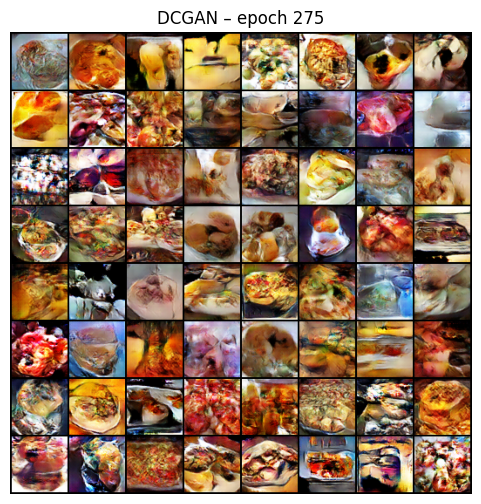

[DCGAN] Epoch 276 | D: 0.438 | G: 3.543 | D(x): 0.84 | D(G(z)): 0.06
[DCGAN] Epoch 277 | D: 0.444 | G: 3.620 | D(x): 0.84 | D(G(z)): 0.06
[DCGAN] Epoch 278 | D: 0.445 | G: 3.646 | D(x): 0.84 | D(G(z)): 0.06
[DCGAN] Epoch 279 | D: 0.411 | G: 3.779 | D(x): 0.85 | D(G(z)): 0.05
[DCGAN] Epoch 280 | D: 0.422 | G: 3.766 | D(x): 0.85 | D(G(z)): 0.05
[DCGAN] Epoch 281 | D: 0.405 | G: 3.863 | D(x): 0.85 | D(G(z)): 0.04
[DCGAN] Epoch 282 | D: 0.429 | G: 3.828 | D(x): 0.85 | D(G(z)): 0.05
[DCGAN] Epoch 283 | D: 0.421 | G: 3.885 | D(x): 0.85 | D(G(z)): 0.05
[DCGAN] Epoch 284 | D: 0.416 | G: 3.934 | D(x): 0.86 | D(G(z)): 0.05
[DCGAN] Epoch 285 | D: 0.442 | G: 3.977 | D(x): 0.85 | D(G(z)): 0.05
[DCGAN] Epoch 286 | D: 0.427 | G: 3.957 | D(x): 0.85 | D(G(z)): 0.05
[DCGAN] Epoch 287 | D: 0.415 | G: 4.022 | D(x): 0.86 | D(G(z)): 0.04
[DCGAN] Epoch 288 | D: 0.413 | G: 4.035 | D(x): 0.85 | D(G(z)): 0.04
[DCGAN] Epoch 289 | D: 0.734 | G: 4.324 | D(x): 0.83 | D(G(z)): 0.09
[DCGAN] Epoch 290 | D: 2.246 | G: 

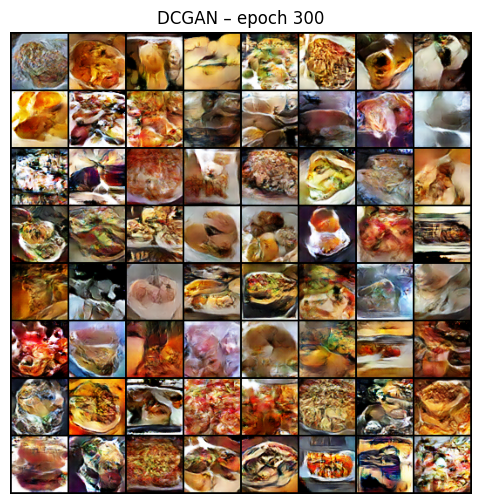

DCGAN: 300 epochs done, total training time 32.8 min


In [25]:
TRAIN_EPOCHS = 300

set_seed()
run_dc = new_run(G_dc, D_dc, "DCGAN")
hist_dc = train_epochs(run_dc, TRAIN_EPOCHS, show_every=25)   # prints every epoch, shows samples every 25

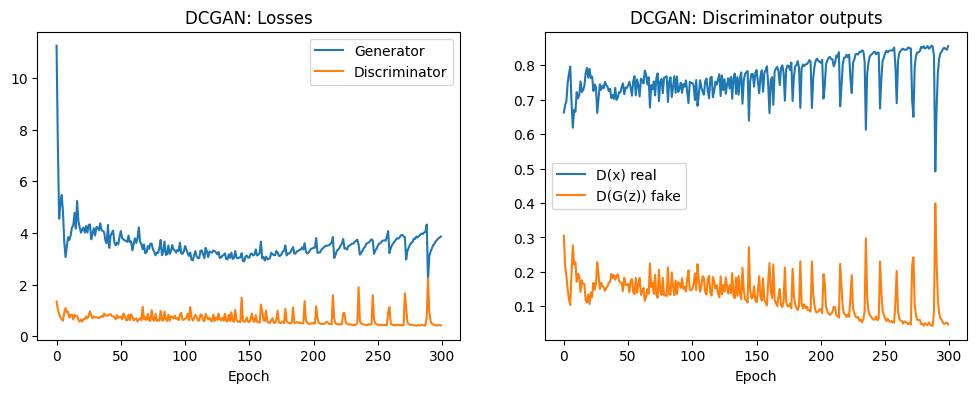

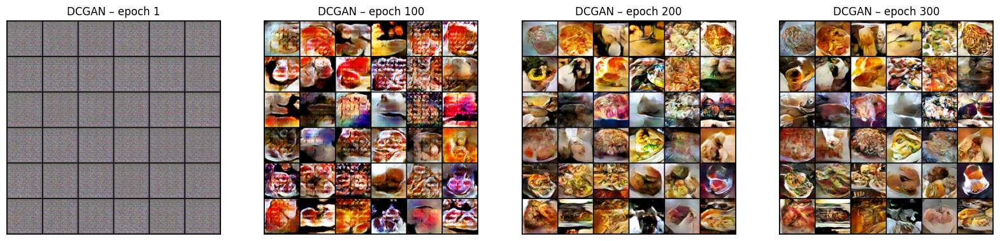

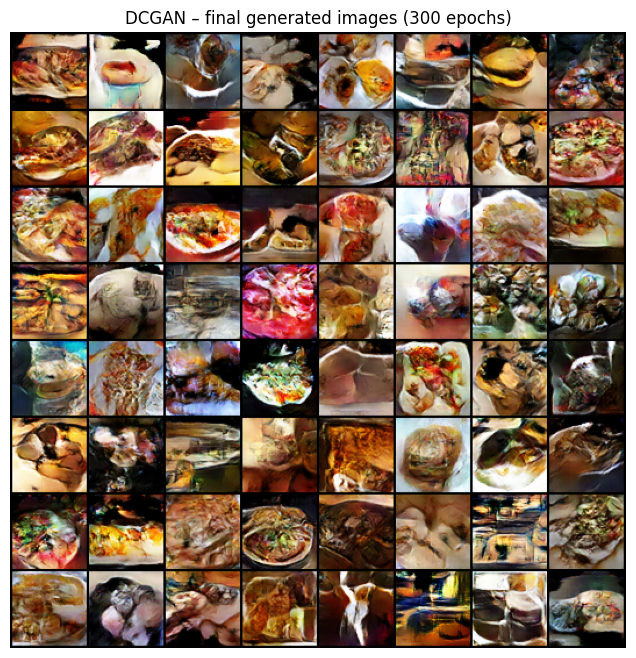

In [26]:
plot_history(hist_dc, "DCGAN")
show_progress(hist_dc, "DCGAN")

G_dc.eval()
with torch.no_grad():
    samples_dc = G_dc(torch.randn(64, NZ, device=device)).cpu()
show_grid(samples_dc, "DCGAN – final generated images (300 epochs)")
torch.save(G_dc.state_dict(), "dcgan_G.pth")

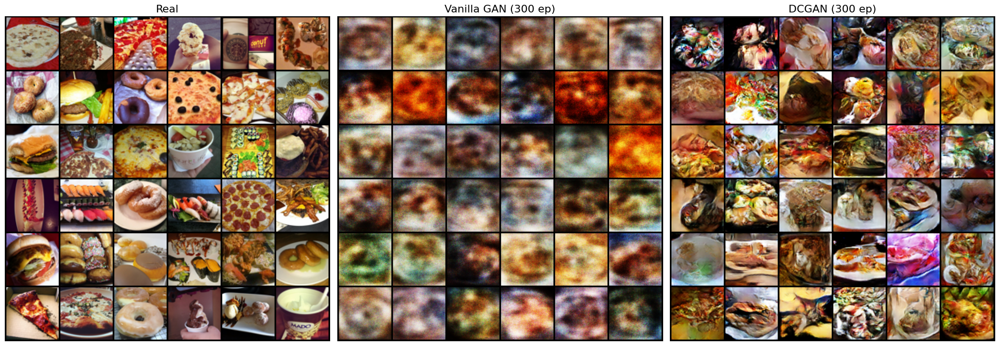

In [27]:
G_van.eval(); G_dc.eval()
with torch.no_grad():
    samples_van = G_van(torch.randn(64, NZ, device=device)).cpu()
    samples_dc  = G_dc(torch.randn(64, NZ, device=device)).cpu()

fig, axs = plt.subplots(1, 3, figsize=(21, 7.5))
real_batch = data[torch.randperm(len(data))[:36]]
for a, t, x in zip(axs, ["Real", f"Vanilla GAN ({run_van['epoch']} ep)", f"DCGAN ({run_dc['epoch']} ep)"],
                   [real_batch, samples_van[:36], samples_dc[:36]]):
    g = vutils.make_grid(x, nrow=6, normalize=True, value_range=(-1, 1))
    a.imshow(g.permute(1, 2, 0)); a.set_title(t, fontsize=16); a.axis("off")
plt.tight_layout(); plt.show()